In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_covtype
from sklearn.model_selection import train_test_split
from sklearn.ensemble import AdaBoostClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score

In [2]:
covtype_data = fetch_covtype(return_X_y=False)
X_forest = covtype_data.data
y_forest = covtype_data.target
features = covtype_data.feature_names

df_med = pd.DataFrame(X_forest, columns = features)
df_med['Target_Tree_Type'] = y_forest
df_med.head()

,Elevation,Aspect,Slope,Horizontal_Distance_To_Hydrology,Vertical_Distance_To_Hydrology,Horizontal_Distance_To_Roadways,Hillshade_9am,Hillshade_Noon,Hillshade_3pm,Horizontal_Distance_To_Fire_Points,...,Soil_Type_31,Soil_Type_32,Soil_Type_33,Soil_Type_34,Soil_Type_35,Soil_Type_36,Soil_Type_37,Soil_Type_38,Soil_Type_39,Target_Tree_Type
0,2596.0,51.0,3.0,258.0,0.0,510.0,221.0,232.0,148.0,6279.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
1,2590.0,56.0,2.0,212.0,-6.0,390.0,220.0,235.0,151.0,6225.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5
2,2804.0,139.0,9.0,268.0,65.0,3180.0,234.0,238.0,135.0,6121.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
3,2785.0,155.0,18.0,242.0,118.0,3090.0,238.0,238.0,122.0,6211.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,2
4,2595.0,45.0,2.0,153.0,-1.0,391.0,220.0,234.0,150.0,6172.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5


In [3]:
class_count = df_med['Target_Tree_Type'].value_counts().sort_index()
class_count

Target_Tree_Type
1    211840
2    283301
3     35754
4      2747
5      9493
6     17367
7     20510
Name: count, dtype: int64

In [4]:
from sklearn.utils.class_weight import compute_class_weight

# 1. Shift target labels from (1 to 7) to (0 to 6) for XGBoost compatibility
y_forest = df_med['Target_Tree_Type'].values - 1
X_forest = df_med.drop(columns=['Target_Tree_Type']).values

# 2. Downsample to 100k rows while preserving class ratios (stratified split)
X_sub, _, y_sub, _ = train_test_split(X_forest, y_forest, train_size=100000, stratify=y_forest, random_state=42)

# final split for modelling
X_train, X_test, y_train, y_test = train_test_split(X_sub, y_sub, test_size=0.2, stratify=y_sub, random_state=42)
print(f"Training features shape: {X_train.shape}")

Training features shape: (80000, 54)


In [5]:
classes = np.unique(y_train)

# weight = tot samples / (no of classes * no of class samples)
weights = compute_class_weight(class_weight = 'balanced', classes= classes, y = y_train)
class_weights = dict(zip(classes, weights))

print(class_weights)

{0: 0.39181882297625575, 1: 0.29298019453884916, 2: 2.321464844316764, 3: 30.15454202789295, 4: 8.744125040988086, 5: 4.7798291211089206, 6: 4.046944556859571}


In [6]:
# create a weights column for assigning weights to classses as in boosting there isnt a direct feature to plug in weights in formula
weight_array = np.array( [ class_weights[cls] for cls in sorted(class_weights.keys()) ] )

sample_weights_train = weight_array[y_train]
print(f"Sample weights array created. Shape: {sample_weights_train.shape}")
print(f"First 5 sample weights: {sample_weights_train[:5]}")
print(f"First 5 true classes:   {y_train[:5]}")

Sample weights array created. Shape: (80000,)
First 5 sample weights: [0.39181882 4.04694456 2.32146484 4.77982912 0.29298019]
First 5 true classes:   [0 6 2 5 1]


In [7]:
from sklearn.model_selection import GridSearchCV

param_grid = {'n_estimators': [20,50,100]}
grid_search = {
    "AdaBoost" : GridSearchCV(AdaBoostClassifier(random_state=42), param_grid, cv=3, scoring='f1_macro', n_jobs=-1),
    "GradientBoost" : GridSearchCV(GradientBoostingClassifier(random_state=42), param_grid, cv=3, scoring='f1_macro', n_jobs=-1),
    "XGBoost": GridSearchCV(XGBClassifier(objective='multi:softprob', num_class=7, random_state=42), param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
}

results = []
for name, grid in grid_search.items():
    print(f"Running GridSearch for {name}...")
    
    # pass sample weights so the cross-validation folds adhere to class balancing
    grid.fit(X_train, y_train, sample_weight=sample_weights_train)
    
    print(f"Best n_estimators for {name}: {grid.best_params_['n_estimators']}")
    print(f"Best CV Macro F1-Score: {grid.best_score_:.4f}\n")

    results.append({
        'Model': name,
        'Best_n_estimators': grid.best_params_['n_estimators'],
        'Best_Score': grid.best_score_
    })

df_res = pd.DataFrame(results)

Running GridSearch for AdaBoost...
Best n_estimators for AdaBoost: 50
Best CV Macro F1-Score: 0.2415

Running GridSearch for GradientBoost...
Best n_estimators for GradientBoost: 100
Best CV Macro F1-Score: 0.6065

Running GridSearch for XGBoost...
Best n_estimators for XGBoost: 100
Best CV Macro F1-Score: 0.7805



In [8]:
import time

models = {
    "AdaBoost": AdaBoostClassifier(n_estimators=50, random_state=42),
    "GradientBoosting": GradientBoostingClassifier(n_estimators=100, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=100, objective='multi:softprob', num_class=7, random_state=42)
}

predictions = {}
for name, model in models.items():
    print(f"=== Training {name} ===")
    start_time = time.time()

    model.fit(X_train, y_train, sample_weight = sample_weights_train)
    elapsed_time = time.time() - start_time
    print(f"{name} trained in {elapsed_time:.2f} seconds.")
    
    predictions[name] = model.predict(X_test)
    print("-" * 30)

=== Training AdaBoost ===
AdaBoost trained in 13.87 seconds.
------------------------------
=== Training GradientBoosting ===
GradientBoosting trained in 297.03 seconds.
------------------------------
=== Training XGBoost ===
XGBoost trained in 4.00 seconds.
------------------------------


In [9]:
for name in models.keys():
    print(f"\n==================== {name} Classification Report ====================")
    # Adding +1 to labels to match your original tree categories (1 to 7)
    print(classification_report(y_test + 1, predictions[name] + 1, zero_division=0))


==================== AdaBoost Classification Report ====================
              precision    recall  f1-score   support

           1       0.52      0.76      0.62      7292
           2       0.70      0.05      0.09      9752
           3       0.37      0.31      0.34      1231
           4       0.00      0.00      0.00        94
           5       0.04      0.20      0.07       327
           6       0.11      0.82      0.19       598
           7       0.13      0.30      0.18       706

    accuracy                           0.36     20000
   macro avg       0.27      0.35      0.21     20000
weighted avg       0.56      0.36      0.30     20000


==================== GradientBoosting Classification Report ====================
              precision    recall  f1-score   support

           1       0.71      0.71      0.71      7292
           2       0.84      0.58      0.69      9752
           3       0.74      0.76      0.75      1231
           4       0.54      0

In [10]:
# improving XGB
xgb_advanced = XGBClassifier(n_estimators=200, learning_rate=0.05, # lowering learning rate requires more trees but generalises better
                             objective='multi:softprob', num_class=7, early_stopping_rounds=10, # STOP if validation loss doesnt improve over 10 trees
                             random_state=42)

xgb_advanced.fit(X_train, y_train, sample_weight = sample_weights_train, eval_set=[(X_test,y_test)], verbose=50)

[0]	validation_0-mlogloss:1.87717
[50]	validation_0-mlogloss:0.91441
[100]	validation_0-mlogloss:0.73978
[150]	validation_0-mlogloss:0.66679
[199]	validation_0-mlogloss:0.62235


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=10,
              enable_categorical=False, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.05, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=200,
              n_jobs=None, num_class=7, ...)

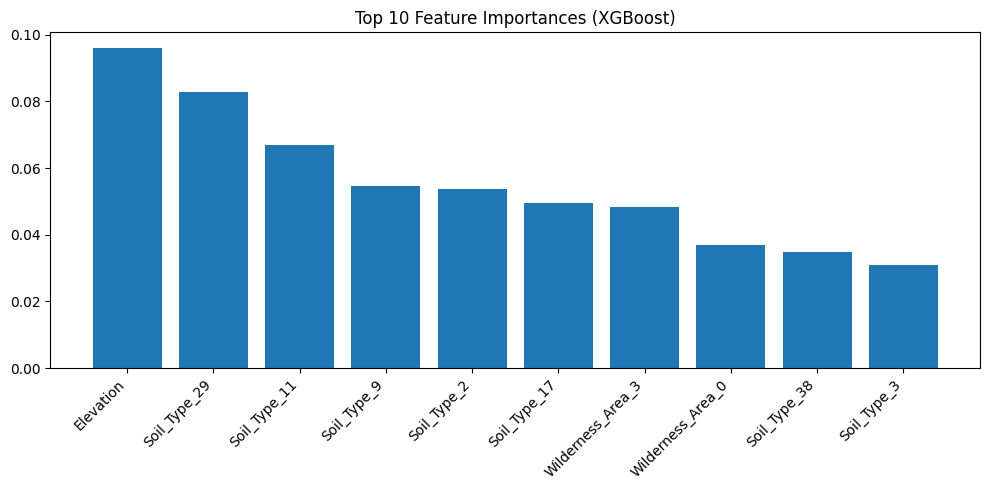

In [11]:
xgb_regularised = XGBClassifier(n_estimators=300,learning_rate=0.05, max_depth=5, reg_lambda=2.0, # L2 Regularization
                    colsample_bytree=0.8,    # Feature subsampling
                    objective='multi:softprob', num_class=7, early_stopping_rounds=15, random_state=42)

importances = models["XGBoost"].feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(10, 5))
plt.title("Top 10 Feature Importances (XGBoost)")
plt.bar(range(10), importances[indices[:10]], align="center")
# map back to actual feature names if available, otherwise indices
plt.xticks(range(10), [covtype_data.feature_names[i] for i in indices[:10]], rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [12]:
# 1. Re-initialize XGBoost with regularization and early stopping
xgb_advanced = XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5, reg_lambda=2.0,            
    colsample_bytree=0.8, # Force trees to ignore some features (like Elevation) 20% of the time
    objective='multi:softprob', num_class=7, early_stopping_rounds=15,  # Stop if validation loss doesn't improve for 15 straight trees
    random_state=42
)

xgb_advanced.fit(X_train, y_train, sample_weight=sample_weights_train, eval_set=[(X_test, y_test)], verbose=50)
y_pred_adv = xgb_advanced.predict(X_test)

print("\n==================== Advanced XGBoost Report ====================")
print(classification_report(y_test + 1, y_pred_adv + 1, zero_division=0))

[0]	validation_0-mlogloss:1.89417
[50]	validation_0-mlogloss:0.98898
[100]	validation_0-mlogloss:0.81167
[150]	validation_0-mlogloss:0.74181
[200]	validation_0-mlogloss:0.69726
[250]	validation_0-mlogloss:0.66459
[300]	validation_0-mlogloss:0.63457
[350]	validation_0-mlogloss:0.61191
[400]	validation_0-mlogloss:0.59048
[450]	validation_0-mlogloss:0.57063
[499]	validation_0-mlogloss:0.55277

==================== Advanced XGBoost Report ====================
              precision    recall  f1-score   support

           1       0.76      0.79      0.78      7292
           2       0.87      0.69      0.77      9752
           3       0.78      0.82      0.80      1231
           4       0.73      0.88      0.80        94
           5       0.25      0.94      0.40       327
           6       0.53      0.84      0.65       598
           7       0.63      0.97      0.77       706

    accuracy                           0.75     20000
   macro avg       0.65      0.85      0.71     2000

### Play With Numbers

In [13]:
# Dampen the extreme weights using a square root to balance overall accuracy with minority recall
dampened_weights = {cls: np.sqrt(w) for cls, w in class_weights.items()}
sample_weights_dampened = np.array([dampened_weights[cls] for cls in y_train])

print("New Dampened Weights (closer together, less extreme):")
for cls, w in dampened_weights.items():
    print(f"Category {cls+1}: {w:.4f}")

New Dampened Weights (closer together, less extreme):
Category 1: 0.6260
Category 2: 0.5413
Category 3: 1.5236
Category 4: 5.4913
Category 5: 2.9570
Category 6: 2.1863
Category 7: 2.0117


In [14]:
# Re-initialize XGBoost with regularization and early stopping 
xgb_advanced = XGBClassifier(n_estimators=1500, learning_rate=0.03, max_depth=7, reg_lambda=5.0,            
    colsample_bytree=0.75, # Force trees to ignore some features (like Elevation) 25% of the time
    objective='multi:softprob', num_class=7, early_stopping_rounds=30,  # Stop if validation loss doesn't improve for 15 straight trees
    random_state=42
)

# dampening weights as extreme weight reduce accuracy; but catch rare samples fast
# xgb_advanced.fit(X_train, y_train, sample_weight=sample_weights_train, eval_set=[(X_test, y_test)], verbose=50)
xgb_advanced.fit(X_train, y_train, sample_weight=sample_weights_dampened, eval_set=[(X_test, y_test)], verbose=100)
y_pred_adv = xgb_advanced.predict(X_test)

print("\n==================== Advanced XGBoost Report ====================")
print(classification_report(y_test + 1, y_pred_adv + 1, zero_division=0))

[0]	validation_0-mlogloss:1.32391
[100]	validation_0-mlogloss:0.62403
[200]	validation_0-mlogloss:0.51676
[300]	validation_0-mlogloss:0.47583
[400]	validation_0-mlogloss:0.45092
[500]	validation_0-mlogloss:0.43196
[600]	validation_0-mlogloss:0.41137
[700]	validation_0-mlogloss:0.39343
[800]	validation_0-mlogloss:0.37716
[900]	validation_0-mlogloss:0.36390
[1000]	validation_0-mlogloss:0.35373
[1100]	validation_0-mlogloss:0.34389
[1200]	validation_0-mlogloss:0.33613
[1300]	validation_0-mlogloss:0.32636
[1400]	validation_0-mlogloss:0.31895
[1499]	validation_0-mlogloss:0.31110

==================== Advanced XGBoost Report ====================
              precision    recall  f1-score   support

           1       0.87      0.87      0.87      7292
           2       0.90      0.88      0.89      9752
           3       0.89      0.91      0.90      1231
           4       0.84      0.81      0.83        94
           5       0.75      0.80      0.77       327
           6       0.78     

### Functionality Based Feature Engineering

In [15]:
# 1. Convert back to a temporary DataFrame using the full dataset array
df_engineered = pd.DataFrame(X_sub, columns=covtype_data.feature_names)

# 2. Calculate the true Euclidean (diagonal) distance to water
df_engineered['True_Distance_To_Hydrology'] = np.sqrt(
    df_engineered['Horizontal_Distance_To_Hydrology']**2 + 
    df_engineered['Vertical_Distance_To_Hydrology']**2
)

# 3. Calculate absolute elevation of the water table
df_engineered['Water_Table_Elevation'] = (
    df_engineered['Elevation'] - df_engineered['Vertical_Distance_To_Hydrology']
)

# 4. Create an overall distance metric combining roads and fires
df_engineered['Road_Fire_Proximity_Sum'] = (
    df_engineered['Horizontal_Distance_To_Roadways'] + 
    df_engineered['Horizontal_Distance_To_Fire_Points']
)

# 5. Extract our new expanded array of features
X_engineered = df_engineered.values

print(f"Old feature count: {X_sub.shape[1]}")
print(f"New engineered feature count: {X_engineered.shape[1]}")

Old feature count: 54
New engineered feature count: 57


In [16]:
# Re-split the engineered features
X_train_eng, X_test_eng, y_train_eng, y_test_eng = train_test_split(
    X_engineered, y_sub, test_size=0.2, stratify=y_sub, random_state=42
)

# Initialize using your exact tuned hyperparameters
xgb_maximized = XGBClassifier(
    n_estimators=1500,
    learning_rate=0.03,
    max_depth=7,
    min_child_weight=3, # Requires more samples to create a leaf, preventing overfitting on rare noise
    reg_lambda=5.0,
    colsample_bytree=0.75,
    objective='multi:softprob',
    num_class=7,
    early_stopping_rounds=30,
    random_state=42
)

# Fit using the engineered features
xgb_maximized.fit(
    X_train_eng, y_train_eng, 
    sample_weight=sample_weights_dampened,
    eval_set=[(X_test_eng, y_test_eng)], 
    verbose=100
)

# Evaluate the new ceiling
y_pred_max = xgb_maximized.predict(X_test_eng)
print("\n==================== Maximized XGBoost Report (With Feature Engineering) ====================")
print(classification_report(y_test_eng + 1, y_pred_max + 1, zero_division=0))

[0]	validation_0-mlogloss:1.31982
[100]	validation_0-mlogloss:0.60098
[200]	validation_0-mlogloss:0.49902
[300]	validation_0-mlogloss:0.45699
[400]	validation_0-mlogloss:0.42808
[500]	validation_0-mlogloss:0.40260
[600]	validation_0-mlogloss:0.37990
[700]	validation_0-mlogloss:0.36079
[800]	validation_0-mlogloss:0.34619
[900]	validation_0-mlogloss:0.33229
[1000]	validation_0-mlogloss:0.31760
[1100]	validation_0-mlogloss:0.30682
[1200]	validation_0-mlogloss:0.29765
[1300]	validation_0-mlogloss:0.28870
[1400]	validation_0-mlogloss:0.28263
[1499]	validation_0-mlogloss:0.27530

==================== Maximized XGBoost Report (With Feature Engineering) ====================
              precision    recall  f1-score   support

           1       0.89      0.89      0.89      7292
           2       0.91      0.90      0.91      9752
           3       0.91      0.94      0.92      1231
           4       0.84      0.82      0.83        94
           5       0.80      0.82      0.81       327
